In [2]:
# import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
cf_data = pd.read_csv('fraud_data.csv')
cf_data.head()

,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
0,04-01-2019 00:58,"""Stokes, Christiansen and Sipes""",grocery_net,14.37,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a3806e984cec6ac0096d8184c64ad3a1,65.654142,-164.722603,1
1,04-01-2019 15:06,Predovic Inc,shopping_net,966.11,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a59185fe1b9ccf21323f581d7477573f,65.468863,-165.473127,1
2,04-01-2019 22:37,Wisozk and Sons,misc_pos,49.61,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,86ba3a888b42cd3925881fa34177b4e0,65.347667,-165.914542,1
3,04-01-2019 23:06,Murray-Smitham,grocery_pos,295.26,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,3a068fe1d856f0ecedbed33e4b5f4496,64.445035,-166.080207,1
4,04-01-2019 23:59,Friesen Lt,health_fitness,18.17,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,891cdd1191028759dc20dc224347a0ff,65.447094,-165.446843,1


In [4]:
cf_data

,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
0,04-01-2019 00:58,"""Stokes, Christiansen and Sipes""",grocery_net,14.37,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a3806e984cec6ac0096d8184c64ad3a1,65.654142,-164.722603,1
1,04-01-2019 15:06,Predovic Inc,shopping_net,966.11,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a59185fe1b9ccf21323f581d7477573f,65.468863,-165.473127,1
2,04-01-2019 22:37,Wisozk and Sons,misc_pos,49.61,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,86ba3a888b42cd3925881fa34177b4e0,65.347667,-165.914542,1
3,04-01-2019 23:06,Murray-Smitham,grocery_pos,295.26,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,3a068fe1d856f0ecedbed33e4b5f4496,64.445035,-166.080207,1
4,04-01-2019 23:59,Friesen Lt,health_fitness,18.17,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,891cdd1191028759dc20dc224347a0ff,65.447094,-165.446843,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14441,22-01-2019 00:37,Hudson-Grady,shopping_pos,122.00,Athena,OR,45.8289,-118.4971,1302,Dealer,18-10-1976,699a4c06b22711bf3e0d8ef91232d356,46.442439,-118.524214,0
14442,22-01-2019 00:41,"""Nienow, Ankunding and Collie""",misc_pos,9.07,Gardiner,OR,43.7857,-124.1437,260,"""Engineer, maintenance""",01-09-1956,080d620d24815c7d6c637cf0b71dde8e,42.901265,-124.995317,0
14443,22-01-2019 00:42,Pacocha-O'Reilly,grocery_pos,104.84,Alva,WY,44.6873,-104.4414,110,"""Administrator, local government""",16-05-1973,3c346c8cd627c5fe3ed57430db2e9ae7,45.538062,-104.542117,0
14444,22-01-2019 00:48,"""Bins, Balistreri and Beatty""",shopping_pos,268.16,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,e66ffcc95ba7fc490486242af1205d04,64.081462,-165.898698,0


In [ ]:
cf_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14446 entries, 0 to 14445
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   trans_date_trans_time  14446 non-null  object 
 1   merchant               14446 non-null  object 
 2   category               14446 non-null  object 
 3   amt                    14446 non-null  float64
 4   city                   14446 non-null  object 
 5   state                  14446 non-null  object 
 6   lat                    14446 non-null  float64
 7   long                   14446 non-null  float64
 8   city_pop               14446 non-null  int64  
 9   job                    14446 non-null  object 
 10  dob                    14446 non-null  object 
 11  trans_num              14446 non-null  object 
 12  merch_lat              14446 non-null  float64
 13  merch_long             14446 non-null  float64
 14  is_fraud               14446 non-null  object 
dtypes:

In [ ]:
cf_data.describe()

,amt,lat,long,city_pop,merch_lat,merch_long
count,14446.000000,14446.000000,14446.000000,1.444600e+04,14446.000000,14446.000000
mean,124.430073,39.787692,-110.874225,1.065370e+05,39.787991,-110.874892
std,231.352587,5.317039,12.985813,2.902916e+05,5.360593,12.995596
min,1.000000,20.027100,-165.672300,4.600000e+01,19.032689,-166.670685
25%,12.080000,36.715400,-120.415800,4.930000e+02,36.794655,-120.146253
50%,51.520000,39.666200,-111.098500,1.645000e+03,39.620953,-111.192629
75%,101.030000,41.940400,-101.136000,3.543900e+04,42.275740,-100.446822
max,3261.470000,66.693300,-89.628700,2.383912e+06,67.510267,-88.646366


**Data Cleaning**

In [ ]:
# COUNTS OF FRAUD AND NON-FRAUD TRANS
cf_data['is_fraud'].value_counts()

,count
is_fraud,
0,12600
1,1781
"1""2020-12-24 16:56:24""",1
"0""2019-01-01 00:00:44""",1


In [ ]:
# CORRECTLY FORMAT THE CONTENT OF 'is_fraud' COLUMN
cf_data['is_fraud'] = cf_data.apply(lambda row: int(str(row['is_fraud'])[0]) if str(row['is_fraud'])[0].isdigit() else 0, axis=1)
cf_data['is_fraud'].value_counts()

,count
is_fraud,
0,12601
1,1782


In [ ]:
cf_data.describe(include='all')

,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
count,14383,14383,14383,14383.000000,14383,14383,14383.000000,14383.000000,1.438300e+04,14383,14383,14383,14383.000000,14383.000000,14383.000000
unique,12126,693,14,NaN,176,13,NaN,NaN,NaN,163,187,14383,NaN,NaN,NaN
top,21-01-2019 23:09,Kilback LLC,grocery_pos,NaN,Phoenix,CA,NaN,NaN,NaN,"""Surveyor, minerals""",17-07-1989,a3806e984cec6ac0096d8184c64ad3a1,NaN,NaN,NaN
freq,5,58,1591,NaN,297,3366,NaN,NaN,NaN,250,197,1,NaN,NaN,NaN
mean,NaN,NaN,NaN,122.719068,NaN,NaN,39.761571,-110.835395,1.063921e+05,NaN,NaN,NaN,39.761755,-110.836186,0.123896
std,NaN,NaN,NaN,228.879064,NaN,NaN,5.266532,12.877931,2.900439e+05,NaN,NaN,NaN,5.309190,12.887765,0.329475
min,NaN,NaN,NaN,1.000000,NaN,NaN,20.027100,-165.672300,4.600000e+01,NaN,NaN,NaN,19.032689,-166.670685,0.000000
25%,NaN,NaN,NaN,11.945000,NaN,NaN,36.715400,-120.282400,4.930000e+02,NaN,NaN,NaN,36.768908,-120.095775,0.000000
50%,NaN,NaN,NaN,51.290000,NaN,NaN,39.666200,-111.098500,1.645000e+03,NaN,NaN,NaN,39.613766,-111.203646,0.000000
75%,NaN,NaN,NaN,100.140000,NaN,NaN,41.940400,-101.136000,3.543900e+04,NaN,NaN,NaN,42.275391,-100.556920,0.000000


In [ ]:
cf_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14383 entries, 0 to 14445
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   trans_date_trans_time  14383 non-null  object 
 1   merchant               14383 non-null  object 
 2   category               14383 non-null  object 
 3   amt                    14383 non-null  float64
 4   city                   14383 non-null  object 
 5   state                  14383 non-null  object 
 6   lat                    14383 non-null  float64
 7   long                   14383 non-null  float64
 8   city_pop               14383 non-null  int64  
 9   job                    14383 non-null  object 
 10  dob                    14383 non-null  object 
 11  trans_num              14383 non-null  object 
 12  merch_lat              14383 non-null  float64
 13  merch_long             14383 non-null  float64
 14  is_fraud               14383 non-null  int64  
dtypes: floa

In [ ]:
# CHECK FOR MISSING VALUES
cf_data.isna().sum().sum()

0

In [ ]:
# convert 'trans_date_trans_time' and 'dob' columns to datetime
cf_data['trans_date_trans_time'] = pd.to_datetime(cf_data['trans_date_trans_time'], format='%d-%m-%Y %H:%M')
cf_data['dob'] = pd.to_datetime(cf_data['dob'], format='%d-%m-%Y')
# cf_data['trans_date_trans_time'].dt.day   ## USE TO ACCESS
print(cf_data[['trans_date_trans_time', 'dob']].info())

<class 'pandas.core.frame.DataFrame'>
Index: 14383 entries, 0 to 14445
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   trans_date_trans_time  14383 non-null  datetime64[ns]
 1   dob                    14383 non-null  datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 337.1 KB
None


In [ ]:
cf_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14383 entries, 0 to 14445
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   trans_date_trans_time  14383 non-null  datetime64[ns]
 1   merchant               14383 non-null  object        
 2   category               14383 non-null  object        
 3   amt                    14383 non-null  float64       
 4   city                   14383 non-null  object        
 5   state                  14383 non-null  object        
 6   lat                    14383 non-null  float64       
 7   long                   14383 non-null  float64       
 8   city_pop               14383 non-null  int64         
 9   job                    14383 non-null  object        
 10  dob                    14383 non-null  datetime64[ns]
 11  trans_num              14383 non-null  object        
 12  merch_lat              14383 non-null  float64       
 13  merch_

In [ ]:
cf_data.columns.values

array(['trans_date_trans_time', 'merchant', 'category', 'amt', 'city',
       'state', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num',
       'merch_lat', 'merch_long', 'is_fraud'], dtype=object)

In [ ]:
# CHANGE COLUMNS NAMES WITH MORE APPROPRIATE NAMES
cols = ['trans_date_time', 'merchant_name', 'purchase_category', 'amount', 'purchase_city',
       'purchase_state', 'purchase_city_lat', 'purchase_city_long', 'city_population', 'occupation', 'dateofbirth', 'trans_num',
       'merch_lat', 'merch_long', 'is_fraud']
cf_data.columns = cols
cf_data.head(2)

,trans_date_time,merchant_name,purchase_category,amount,purchase_city,purchase_state,purchase_city_lat,purchase_city_long,city_population,occupation,dateofbirth,trans_num,merch_lat,merch_long,is_fraud
0,2019-01-04 00:58:00,"""Stokes, Christiansen and Sipes""",grocery_net,14.37,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",1939-11-09,a3806e984cec6ac0096d8184c64ad3a1,65.654142,-164.722603,1
1,2019-01-04 15:06:00,Predovic Inc,shopping_net,966.11,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",1939-11-09,a59185fe1b9ccf21323f581d7477573f,65.468863,-165.473127,1


**Get year, month, day - (number and name), time - (day and night) from 'trans_date_time' & age from'dateofbirth**

In [ ]:
cf_data['trans_year'] = cf_data['trans_date_time'].dt.year
cf_data['trans_month'] = cf_data['trans_date_time'].dt.month
cf_data['trans_day'] = cf_data['trans_date_time'].dt.day
cf_data['trans_hour'] = cf_data['trans_date_time'].dt.hour
cf_data['age'] = cf_data['trans_date_time'].dt.year-cf_data['dateofbirth'].dt.year
cf_data.head()

,trans_date_time,merchant_name,purchase_category,amount,purchase_city,purchase_state,purchase_city_lat,purchase_city_long,city_population,occupation,dateofbirth,trans_num,merch_lat,merch_long,is_fraud,trans_year,trans_month,trans_day,trans_hour,age
0,2019-01-04 00:58:00,"""Stokes, Christiansen and Sipes""",grocery_net,14.37,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",1939-11-09,a3806e984cec6ac0096d8184c64ad3a1,65.654142,-164.722603,1,2019,1,4,0,80
1,2019-01-04 15:06:00,Predovic Inc,shopping_net,966.11,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",1939-11-09,a59185fe1b9ccf21323f581d7477573f,65.468863,-165.473127,1,2019,1,4,15,80
2,2019-01-04 22:37:00,Wisozk and Sons,misc_pos,49.61,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",1939-11-09,86ba3a888b42cd3925881fa34177b4e0,65.347667,-165.914542,1,2019,1,4,22,80
3,2019-01-04 23:06:00,Murray-Smitham,grocery_pos,295.26,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",1939-11-09,3a068fe1d856f0ecedbed33e4b5f4496,64.445035,-166.080207,1,2019,1,4,23,80
4,2019-01-04 23:59:00,Friesen Lt,health_fitness,18.17,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",1939-11-09,891cdd1191028759dc20dc224347a0ff,65.447094,-165.446843,1,2019,1,4,23,80


In [ ]:
cf_data.drop(columns=['trans_date_time', 'dateofbirth'], inplace=True)
cf_data.head()

,merchant_name,purchase_category,amount,purchase_city,purchase_state,purchase_city_lat,purchase_city_long,city_population,occupation,trans_num,merch_lat,merch_long,is_fraud,trans_year,trans_month,trans_day,trans_hour,age
0,"""Stokes, Christiansen and Sipes""",grocery_net,14.37,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",a3806e984cec6ac0096d8184c64ad3a1,65.654142,-164.722603,1,2019,1,4,0,80
1,Predovic Inc,shopping_net,966.11,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",a59185fe1b9ccf21323f581d7477573f,65.468863,-165.473127,1,2019,1,4,15,80
2,Wisozk and Sons,misc_pos,49.61,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",86ba3a888b42cd3925881fa34177b4e0,65.347667,-165.914542,1,2019,1,4,22,80
3,Murray-Smitham,grocery_pos,295.26,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",3a068fe1d856f0ecedbed33e4b5f4496,64.445035,-166.080207,1,2019,1,4,23,80
4,Friesen Lt,health_fitness,18.17,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",891cdd1191028759dc20dc224347a0ff,65.447094,-165.446843,1,2019,1,4,23,80


In [ ]:
# SETTING ORDER FOR COLUMN NAMES
new_column_order = ['trans_num', 'trans_year', 'trans_month', 'trans_day', 'trans_hour',
                    'purchase_category', 'purchase_city', 'city_population', 'purchase_state',
                    'purchase_city_lat', 'purchase_city_long', 'amount',
                    'age', 'occupation', 'merchant_name', 'merch_lat', 'merch_long', 'is_fraud']
cf_data = cf_data[new_column_order]
print(cf_data.shape)
cf_data.head()

(14383, 18)


,trans_num,trans_year,trans_month,trans_day,trans_hour,purchase_category,purchase_city,city_population,purchase_state,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,merch_lat,merch_long,is_fraud
0,a3806e984cec6ac0096d8184c64ad3a1,2019,1,4,0,grocery_net,Wales,145,AK,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",65.654142,-164.722603,1
1,a59185fe1b9ccf21323f581d7477573f,2019,1,4,15,shopping_net,Wales,145,AK,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,65.468863,-165.473127,1
2,86ba3a888b42cd3925881fa34177b4e0,2019,1,4,22,misc_pos,Wales,145,AK,64.7556,-165.6723,49.61,80,"""Administrator, education""",Wisozk and Sons,65.347667,-165.914542,1
3,3a068fe1d856f0ecedbed33e4b5f4496,2019,1,4,23,grocery_pos,Wales,145,AK,64.7556,-165.6723,295.26,80,"""Administrator, education""",Murray-Smitham,64.445035,-166.080207,1
4,891cdd1191028759dc20dc224347a0ff,2019,1,4,23,health_fitness,Wales,145,AK,64.7556,-165.6723,18.17,80,"""Administrator, education""",Friesen Lt,65.447094,-165.446843,1


In [ ]:
# Drop 'trans_num' as it is not required here - for model
cf_data.drop(columns=['trans_num'], inplace=True)
cf_data.head()

<ipython-input-44-fdf9fbd6c20f>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cf_data.drop(columns=['trans_num'], inplace=True)


,trans_year,trans_month,trans_day,trans_hour,purchase_category,purchase_city,city_population,purchase_state,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,merch_lat,merch_long,is_fraud
0,2019,1,4,0,grocery_net,Wales,145,AK,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",65.654142,-164.722603,1
1,2019,1,4,15,shopping_net,Wales,145,AK,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,65.468863,-165.473127,1
2,2019,1,4,22,misc_pos,Wales,145,AK,64.7556,-165.6723,49.61,80,"""Administrator, education""",Wisozk and Sons,65.347667,-165.914542,1
3,2019,1,4,23,grocery_pos,Wales,145,AK,64.7556,-165.6723,295.26,80,"""Administrator, education""",Murray-Smitham,64.445035,-166.080207,1
4,2019,1,4,23,health_fitness,Wales,145,AK,64.7556,-165.6723,18.17,80,"""Administrator, education""",Friesen Lt,65.447094,-165.446843,1


**Exploratory Data Analysis And Feature Extraction**

Now that data is in correct format, lets see how likely a transaction is fraudulent with respect to different features and their categories.

EDA And Features Extraction

[x] Transaction Year

[x] Transaction Month

[x] Transaction Day

[x] Transaction Hour

[x] Purchase Category

[x] Purchase City

[x] Purchase State

[ ] Purchase City Locations

[ ] City Population

[ ] Amount

[ ] BirthYear

[ ] Occupation

[ ] Merchant Name

[ ] Merchant Location

In [ ]:
# First see the categories/unique elements present in each column
for col in cf_data.columns.values:
    print(f'Number of unique values in {col}: {len(list(cf_data[col].unique()))}')

Number of unique values in trans_year: 2
Number of unique values in trans_month: 12
Number of unique values in trans_day: 31
Number of unique values in trans_hour: 24
Number of unique values in purchase_category: 14
Number of unique values in purchase_city: 176
Number of unique values in city_population: 174
Number of unique values in purchase_state: 13
Number of unique values in purchase_city_lat: 183
Number of unique values in purchase_city_long: 183
Number of unique values in amount: 9266
Number of unique values in age: 74
Number of unique values in occupation: 163
Number of unique values in merchant_name: 693
Number of unique values in merch_lat: 14376
Number of unique values in merch_long: 14380
Number of unique values in is_fraud: 2


Transaction Year vs Fraud Relation

In [ ]:
trans_year_count = cf_data['trans_year'].value_counts()
# trans_year_count.keys()[0]
trans_year_count

,count
trans_year,
2019,7580
2020,6803


In [ ]:
for year in trans_year_count.keys():
    percent = (cf_data[(cf_data['trans_year']==year) & (cf_data['is_fraud']==1)]['trans_year'].count()/trans_year_count[year])*100
    print(f"Percentage of fraudulent transactions in {year} is: {percent}")

Percentage of fraudulent transactions in 2019 is: 12.902374670184697
Percentage of fraudulent transactions in 2020 is: 11.818315449066588


In [ ]:
cf_data_trans_year = cf_data[['trans_year', 'is_fraud']].groupby(by='trans_year').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_trans_year['total'] = cf_data_trans_year.apply(lambda row: trans_year_count[row['trans_year']], axis=1)
cf_data_trans_year.head()

,trans_year,is_fraud,total
0,2019,978,7580
1,2020,804,6803


In [ ]:
import plotly.express as px
import plotly.graph_objects as go

# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_trans_year['trans_year'],
    y=cf_data_trans_year['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_trans_year['is_fraud']/cf_data_trans_year['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_trans_year['trans_year'],
    y=cf_data_trans_year['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Year',
    xaxis_title='Transaction Year',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
    ),
)
fig.show()

In [ ]:
cf_data_trans_year = cf_data[['trans_year', 'is_fraud']].groupby(by='trans_year').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_trans_year['total'] = cf_data_trans_year.apply(lambda row: trans_year_count[row['trans_year']], axis=1)
cf_data_trans_year.head()

,trans_year,is_fraud,total
0,2019,978,7580
1,2020,804,6803


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_trans_year['trans_year'],
    y=cf_data_trans_year['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_trans_year['is_fraud']/cf_data_trans_year['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_trans_year['trans_year'],
    y=cf_data_trans_year['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Year',
    xaxis_title='Transaction Year',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
    ),
)
fig.show()

In [ ]:
# Observations -

# There is no big difference in fraud percentage for two years
# We might as well drop this column - as it is not giving much of the distinction
cf_data.drop(columns=['trans_year'], inplace=True)
cf_data.head()

,trans_month,trans_day,trans_hour,purchase_category,purchase_city,city_population,purchase_state,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,merch_lat,merch_long,is_fraud
0,1,4,0,grocery_net,Wales,145,AK,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",65.654142,-164.722603,1
1,1,4,15,shopping_net,Wales,145,AK,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,65.468863,-165.473127,1
2,1,4,22,misc_pos,Wales,145,AK,64.7556,-165.6723,49.61,80,"""Administrator, education""",Wisozk and Sons,65.347667,-165.914542,1
3,1,4,23,grocery_pos,Wales,145,AK,64.7556,-165.6723,295.26,80,"""Administrator, education""",Murray-Smitham,64.445035,-166.080207,1
4,1,4,23,health_fitness,Wales,145,AK,64.7556,-165.6723,18.17,80,"""Administrator, education""",Friesen Lt,65.447094,-165.446843,1


**2. Transaction month Vs Fraud Relation**

In [ ]:
trans_month_counts = cf_data['trans_month'].value_counts()
trans_month_counts

,count
trans_month,
1,6743
12,6161
3,220
9,197
2,169
5,167
8,156
10,150
7,125


In [ ]:
cf_data_trans_month = cf_data[['trans_month', 'is_fraud']].groupby(by='trans_month').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_trans_month['total'] = cf_data_trans_month.apply(lambda row: trans_month_counts[row['trans_month']], axis=1)
cf_data_trans_month.head()

,trans_month,is_fraud,total
2,3,220,220
8,9,197,197
1,2,169,169
4,5,167,167
11,12,162,6161


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_trans_month['trans_month'],
    y=cf_data_trans_month['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_trans_month['is_fraud']/cf_data_trans_month['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_trans_month['trans_month'],
    y=cf_data_trans_month['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Month',
    xaxis_title='Transaction Month',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[0, len(cf_data_trans_month['trans_month'])+1]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 1000]  # Set y-axis limits (xlim)
    )
)

fig.show()

In [ ]:
'''
Observation -

The bar plot clearly shows that the transactions occured in months excluding [1st and 12th] are all fraud
This is very interesting and might suggest that data is not real - because it is highly unlikely that fruad are only happening in Jan and Dec months
However, the count of fraud transactions are in similar range for all months - thus 'trans_month' does not provide distinct diff btw fraud and non-fraud transactions - therefore we will drop this column as well
'''

cf_data.drop(columns=['trans_month'], inplace=True)
cf_data.head()

,trans_day,trans_hour,purchase_category,purchase_city,city_population,purchase_state,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,merch_lat,merch_long,is_fraud
0,4,0,grocery_net,Wales,145,AK,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",65.654142,-164.722603,1
1,4,15,shopping_net,Wales,145,AK,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,65.468863,-165.473127,1
2,4,22,misc_pos,Wales,145,AK,64.7556,-165.6723,49.61,80,"""Administrator, education""",Wisozk and Sons,65.347667,-165.914542,1
3,4,23,grocery_pos,Wales,145,AK,64.7556,-165.6723,295.26,80,"""Administrator, education""",Murray-Smitham,64.445035,-166.080207,1
4,4,23,health_fitness,Wales,145,AK,64.7556,-165.6723,18.17,80,"""Administrator, education""",Friesen Lt,65.447094,-165.446843,1


**3. Transaction Day Vs Fraud Relation**

In [ ]:
trans_day_counts = cf_data['trans_day'].value_counts()
# len(trans_day_counts)
trans_day_counts.head()

,count
trans_day,
29,1198
28,1160
27,1053
26,757
31,722


In [ ]:
cf_data_trans_day = cf_data[['trans_day', 'is_fraud']].groupby(by='trans_day').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_trans_day['total'] = cf_data_trans_day.apply(lambda row: trans_day_counts[row['trans_day']], axis=1)
cf_data_trans_day.head()

,trans_day,is_fraud,total
13,14,110,504
12,13,82,454
29,30,80,602
10,11,80,355
0,1,74,540


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_trans_day['trans_day'],
    y=cf_data_trans_day['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_trans_day['is_fraud']/cf_data_trans_day['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_trans_day['trans_day'],
    y=cf_data_trans_day['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Day',
    xaxis_title='Transaction Day',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[0, len(cf_data_trans_day['trans_day'])+1]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 150]  # Set y-axis limits (xlim)
    )
)

fig.show()

In [ ]:
'''
Observations -

The fraud percentage varies across day (numbers) - however the count of fraud transaction is similar for all days
Therefore we will drop 'trans_day' column as well
'''
cf_data.drop(columns=['trans_day'], inplace=True)
cf_data.head()

,trans_hour,purchase_category,purchase_city,city_population,purchase_state,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,merch_lat,merch_long,is_fraud
0,0,grocery_net,Wales,145,AK,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",65.654142,-164.722603,1
1,15,shopping_net,Wales,145,AK,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,65.468863,-165.473127,1
2,22,misc_pos,Wales,145,AK,64.7556,-165.6723,49.61,80,"""Administrator, education""",Wisozk and Sons,65.347667,-165.914542,1
3,23,grocery_pos,Wales,145,AK,64.7556,-165.6723,295.26,80,"""Administrator, education""",Murray-Smitham,64.445035,-166.080207,1
4,23,health_fitness,Wales,145,AK,64.7556,-165.6723,18.17,80,"""Administrator, education""",Friesen Lt,65.447094,-165.446843,1


**4. Transaction Hour Vs Fraud Relation**

In [ ]:
trans_hour_counts = cf_data['trans_hour'].value_counts()
trans_hour_counts.head()

,count
trans_hour,
23,1109
22,1104
20,702
21,691
15,669


In [ ]:
cf_data_trans_hour = cf_data[['trans_hour', 'is_fraud']].groupby(by='trans_hour').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_trans_hour['total'] = cf_data_trans_hour.apply(lambda row: trans_hour_counts[row['trans_hour']], axis=1)
cf_data_trans_hour.head()

,trans_hour,is_fraud,total
23,23,459,1109
22,22,452,1104
1,1,168,607
0,0,168,581
3,3,143,560


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_trans_hour['trans_hour'],
    y=cf_data_trans_hour['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_trans_hour['is_fraud']/cf_data_trans_hour['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_trans_hour['trans_hour'],
    y=cf_data_trans_hour['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Hour',
    xaxis_title='Transaction Hour',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[-1, len(cf_data_trans_hour['trans_hour'])]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 150]  # Set y-axis limits (xlim)
    )
)
fig.show()


Observations -

* The high fraud percentage during night hours indicates that most fraudulent transactions occur at this time
* This clear distinction is very useful features for our model training - so keep the column

**5. Purchase Category Vs Fraud Relation**

In [ ]:
purchase_category_count = cf_data['purchase_category'].value_counts()
purchase_category_count

,count
purchase_category,
grocery_pos,1591
gas_transport,1424
shopping_net,1393
shopping_pos,1347
home,1303
kids_pets,1140
personal_care,988
entertainment,949
health_fitness,890


In [ ]:
purchase_category_count = cf_data['purchase_category'].value_counts()
purchase_category_count

,count
purchase_category,
grocery_pos,1591
gas_transport,1424
shopping_net,1393
shopping_pos,1347
home,1303
kids_pets,1140
personal_care,988
entertainment,949
health_fitness,890


In [ ]:
cf_data_purchase_category = cf_data[['purchase_category', 'is_fraud']].groupby(by='purchase_category').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_purchase_category['total'] = cf_data_purchase_category.apply(lambda row: purchase_category_count[row['purchase_category']], axis=1)
cf_data_purchase_category.head()

,purchase_category,is_fraud,total
4,grocery_pos,433,1591
11,shopping_net,381,1393
8,misc_net,217,815
12,shopping_pos,187,1347
2,gas_transport,153,1424


In [ ]:
#  Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_purchase_category['purchase_category'],
    y=cf_data_purchase_category['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_purchase_category['is_fraud']/cf_data_purchase_category['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_purchase_category['purchase_category'],
    y=cf_data_purchase_category['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Purchase Category',
    xaxis_title='Purchase Category',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[-1, len(cf_data_purchase_category['purchase_category'])]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 150]  # Set y-axis limits (xlim)
    )
)
fig.show()

Observations -

* 'purchase_category' - useful feature - since there is diff btw the fraud percentages

**6. Purchase City Vs Fraud Relation**

In [ ]:
purchase_city_count = cf_data['purchase_city'].value_counts()
print(f"Total Number of cities: {len(purchase_city_count)}")
purchase_city_count.head()

Total Number of cities: 176


,count
purchase_city,
Phoenix,297
Centerview,197
Orient,192
Sutherland,187
Fort Washakie,187


In [ ]:
cf_data_purchase_city = cf_data[['purchase_city', 'is_fraud']].groupby(by='purchase_city').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_purchase_city['total'] = cf_data_purchase_city.apply(lambda row: purchase_city_count[row['purchase_city']], axis=1)

# To show the percentage diff btw the sorted cf_data - we will select the first 15 and last 15 rows
cf_data_purchase_city = pd.concat([cf_data_purchase_city.head(10), cf_data_purchase_city.tail(10)], ignore_index=True)
# cf_data_purchase_city = cf_data_purchase_city.head(30)
# cf_data_purchase_city = cf_data_purchase_city.tail(30)
cf_data_purchase_city.head()

,purchase_city,is_fraud,total
0,Albuquerque,24,81
1,Aurora,23,47
2,Fort Washakie,21,187
3,Glendale,20,150
4,Mesa,20,120


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_purchase_city['purchase_city'],
    y=cf_data_purchase_city['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_purchase_city['is_fraud']/cf_data_purchase_city['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_purchase_city['purchase_city'],
    y=cf_data_purchase_city['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Purchase City (Top 10 and Bottom 10)',
    xaxis_title='Purchase City',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[-1, len(cf_data_purchase_city['purchase_city'])]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 150]  # Set y-axis limits (xlim)
    )
)
fig.show()

Visualizing city coordinates with fraud count

In [ ]:
maps = cf_data[cf_data['is_fraud'] == 1][['purchase_city', 'purchase_city_lat', 'purchase_city_long']].drop_duplicates().sort_values('purchase_city').reset_index(drop=True)

count = cf_data[cf_data['is_fraud'] == 1]['purchase_city'].value_counts().rename_axis('purchase_city').reset_index(name='count')
maps = maps.merge(count, on='purchase_city', how='left').sort_values('count')
maps.head()

,purchase_city,purchase_city_lat,purchase_city_long,count
85,Littleton,39.5994,-105.0044,2
84,Laramie,41.4247,-105.4781,2
115,Odessa,38.9829,-93.9757,3
111,Newhall,34.3795,-118.5230,3
169,Vancouver,45.6892,-122.6616,3


In [ ]:
fig = px.density_mapbox(
    maps, lat='purchase_city_lat', lon='purchase_city_long', z='count',
    color_continuous_scale='Plasma', radius=10,
    title='Citywise fraud count Density map',
    center={"lat": 39.8283, "lon": -98.5795}, zoom=3,
    mapbox_style="open-street-map", hover_name='purchase_city',
    height=500, width=1000
)
fig.show()

In [ ]:
# We will drop the (city_lat, city_long) columns as city itself represent it
cf_data.drop(columns=['purchase_city'], inplace=True)
cf_data.head(2)

,trans_hour,purchase_category,city_population,purchase_state,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,merch_lat,merch_long,is_fraud
0,0,grocery_net,145,AK,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",65.654142,-164.722603,1
1,15,shopping_net,145,AK,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,65.468863,-165.473127,1


**7. City Population Vs Fraud Relation**

In [ ]:
fig = px.histogram(cf_data, x="city_population", color='is_fraud', nbins=100)

fig.update_layout(
    width=1000,
    height=400,
    title='Distribution of Population of Cities w.r.t. Fraud Count',
    xaxis_title='City Population (Bins)',
    yaxis_title='Population Count',
    yaxis=dict(
#         range=[0, 500]
    )
)
fig.show()

Observations -

* The distribution of population of cities shows concentration of city population within half million.
* Majority (Almost all) frauds are occured for city population within 49900
* I'm not sure how this will help in model training/prediction - but we will take this column

**8. Purchase State Vs Fraud Relation**

In [ ]:
purchase_state_count = cf_data['purchase_state'].value_counts()
print(len(purchase_state_count))
purchase_state_count.head()

13


,count
purchase_state,
CA,3366
MO,2324
NE,1438
OR,1211
WA,1150


In [ ]:
cf_data_purchase_state = cf_data[['purchase_state', 'is_fraud']].groupby(by='purchase_state').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_purchase_state['total'] = cf_data_purchase_state.apply(lambda row: purchase_state_count[row['purchase_state']], axis=1)
cf_data_purchase_state.head()

,purchase_state,is_fraud,total
2,CA,402,3366
6,MO,262,2324
7,NE,216,1438
9,OR,197,1211
11,WA,126,1150


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_purchase_state['purchase_state'],
    y=cf_data_purchase_state['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_purchase_state['is_fraud']/cf_data_purchase_state['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_purchase_state['purchase_state'],
    y=cf_data_purchase_state['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Purchase State',
    xaxis_title='Purchase State',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[-1, len(cf_data_purchase_state['purchase_state'])]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 150]  # Set y-axis limits (xlim)
    )
)
fig.show()

Observations -

* Fraud percentage varies across states (9-16%) - However, this provides less distinction btw states w.r.t. fraud percentage
* Therefore we will drop this column as well

In [ ]:
cf_data.drop(columns=['purchase_state'], inplace=True)
cf_data.head(2)

,trans_hour,purchase_category,city_population,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,merch_lat,merch_long,is_fraud
0,0,grocery_net,145,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",65.654142,-164.722603,1
1,15,shopping_net,145,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,65.468863,-165.473127,1


**9. Transaction Amount Vs Fraud Relation**

In [ ]:
fig = px.histogram(cf_data, x="amount", color='is_fraud', nbins=30)

fig.update_layout(
    width=1000,
    height=400,
    title='Distribution of Transaction Amount w.r.t. Fraud Count',
    xaxis_title='Amount (Bins)',
    yaxis_title='Amount Count',
    yaxis=dict(
#         range=[0, 500]
    )
)
fig.show()

Observations -

* Fraud amounts are within 0 to 1000

**10. Age Vs Fraud Relation**

In [ ]:
fig = px.histogram(cf_data, x="age", color='is_fraud', nbins=10)

fig.update_layout(
    width=1000,
    height=400,
    title='Distribution of Age w.r.t. Fraud Count',
    xaxis_title='Age (Bins)',
    yaxis_title='Age Count',
    yaxis=dict(
#         range=[0, 500]
    )
)
fig.show()

Observations -

* The distribution of age values shows that - fraud is occured for age groups from 20 to 90 with most for (50-60)

**11. Occupation VS Fraud Relation**

In [ ]:
occupation_counts = cf_data['occupation'].value_counts()
occupation_counts.head()

,count
occupation,
"""Surveyor, minerals""",250
"""Surveyor, land/geomatics""",240
Land/geomatics surveyor,225
Insurance broker,209
Electronics engineer,197


In [ ]:
cf_data_occupation = cf_data[['occupation', 'is_fraud']].groupby(by='occupation').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_occupation['total'] = cf_data_occupation.apply(lambda row: occupation_counts[row['occupation']], axis=1)
cf_data_occupation = pd.concat([cf_data_occupation.head(10), cf_data_occupation.tail(10)], ignore_index=True)
cf_data_occupation.head()

,occupation,is_fraud,total
0,Colour technologist,29,111
1,Systems analyst,28,192
2,"""Surveyor, minerals""",25,250
3,"""Surveyor, land/geomatics""",24,240
4,Naval architect,24,175


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_occupation['occupation'],
    y=cf_data_occupation['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_occupation['is_fraud']/cf_data_occupation['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_occupation['occupation'],
    y=cf_data_occupation['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Occupation (Top 10 & Bottom 10)',
    xaxis_title='Occupation',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[-1, len(cf_data_occupation['occupation'])]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 150]  # Set y-axis limits (xlim)
    )
)
fig.show()

**12. Merchant Name Vs Fraud Relation**

In [ ]:
merchant_counts = cf_data['merchant_name'].value_counts()
merchant_counts.head()

,count
merchant_name,
Kilback LLC,58
Cormier LLC,48
Kutch and Sons,45
Rau and Sons,43
McDermott-Weimann,42


In [ ]:
cf_data_merchant = cf_data[['merchant_name', 'is_fraud']].groupby(by='merchant_name').sum().reset_index().sort_values(by='is_fraud', ascending=False)
cf_data_merchant['total'] = cf_data_merchant.apply(lambda row: merchant_counts[row['merchant_name']], axis=1)
cf_data_merchant = pd.concat([cf_data_merchant.head(10), cf_data_merchant.tail(10)], ignore_index=True)
print(cf_data_merchant.shape)
cf_data_merchant.head()

(20, 3)


,merchant_name,is_fraud,total
0,Kiehn-Emmerich,19,41
1,"""Romaguera, Cruickshank and Greenholt""",18,37
2,Kerluke-Abshire,17,34
3,Kunze Inc,16,31
4,Kilback LLC,15,58


In [ ]:
# Initialize figure
fig = go.Figure()

# Add the first bar plot (total transactions) in light blue
fig.add_trace(go.Bar(
    x=cf_data_merchant['merchant_name'],
    y=cf_data_merchant['total'],
    name='Total Transactions',
    marker_color='lightblue'
))

# Percentage value
percent = (cf_data_merchant['is_fraud']/cf_data_merchant['total'])*100
txt = percent.apply(lambda x: f'{x: .1f}%')

# Add the second bar plot (fraud transactions) in darker blue, to be overlayed on the first
fig.add_trace(go.Bar(
    x=cf_data_merchant['merchant_name'],
    y=cf_data_merchant['is_fraud'],
    name='Fraud Transactions',
    marker_color='blue',
    text=txt,
    textposition='outside'  # Position the text labels outside the bars
))

# Update layout to overlay the bars
fig.update_layout(
    width=1000,
    height=400,
    barmode='overlay',  # Overlay the bars on top of each other
    title='Total vs. Fraudulent Transactions by Merchant Names (Top 10 & Bottom 10)',
    xaxis_title='Merchant Names',
    yaxis_title='Count of Transactions',
    xaxis=dict(
        tickmode='linear',  # Set x-ticks at regular intervals
        tick0=1,  # Starting tick value
        dtick=1,  # Interval between ticks
        range=[-1, len(cf_data_merchant['merchant_name'])]  # Set x-axis limits (xlim)
    ),
    yaxis=dict(
#         range=[0, 150]  # Set y-axis limits (xlim)
    )
)
fig.show()

Unlike the city coordinates the merchant coordinates are not unique - single merchant can have multiple locations - therefore in this case we will only consider the 'merchant_name' and drop the merchant coordinates.

In [ ]:
cf_data.drop(columns=['merch_lat', 'merch_long'], inplace=True)
cf_data.head(2)

,trans_hour,purchase_category,city_population,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,is_fraud
0,0,grocery_net,145,64.7556,-165.6723,14.37,80,"""Administrator, education""","""Stokes, Christiansen and Sipes""",1
1,15,shopping_net,145,64.7556,-165.6723,966.11,80,"""Administrator, education""",Predovic Inc,1


In [ ]:
cf_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14383 entries, 0 to 14445
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   trans_hour          14383 non-null  int32  
 1   purchase_category   14383 non-null  object 
 2   city_population     14383 non-null  int64  
 3   purchase_city_lat   14383 non-null  float64
 4   purchase_city_long  14383 non-null  float64
 5   amount              14383 non-null  float64
 6   age                 14383 non-null  int32  
 7   occupation          14383 non-null  object 
 8   merchant_name       14383 non-null  object 
 9   is_fraud            14383 non-null  int64  
dtypes: float64(3), int32(2), int64(2), object(3)
memory usage: 1.1+ MB


**Label Encoding**

In [ ]:
from sklearn.preprocessing import LabelEncoder

cat_cols = ['purchase_category', 'occupation', 'merchant_name']
le = LabelEncoder()
label_encoder = {}
for col in cat_cols:
    cf_data[col] = le.fit_transform(cf_data[col])
    label_encoder[col] = le

In [ ]:
cf_data.head(2)

,trans_hour,purchase_category,city_population,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name,is_fraud
0,0,3,145,64.7556,-165.6723,14.37,80,1,179,1
1,15,11,145,64.7556,-165.6723,966.11,80,1,564,1


In [ ]:
cf_data.to_csv('credit_data_final.csv',)

In [ ]:
# Split the data into training and testing sets
X = cf_data.drop('is_fraud', axis=1)
y = cf_data['is_fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
X_train

,trans_hour,purchase_category,city_population,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name
4991,15,1,129,44.6255,-116.4493,47.08,55,58,103
4002,17,12,42384,40.3928,-111.7941,8.22,28,90,8
9404,9,3,123,36.4992,-120.0936,41.85,46,79,194
2164,6,4,28278,45.3099,-122.9685,59.13,43,142,229
12196,21,13,3805,40.4815,-92.9951,2.50,69,21,112
...,...,...,...,...,...,...,...,...,...
5386,22,0,1420,43.9210,-122.7806,84.98,55,149,125
2210,8,4,1789,41.1558,-101.1360,105.97,38,103,282
5866,11,8,94014,38.4549,-122.2564,109.15,35,48,328
7933,9,2,331,40.4542,-98.6538,73.79,69,154,189


In [ ]:
y_train

,is_fraud
4991,0
4002,0
9404,0
2164,0
12196,0
...,...
5386,0
2210,0
5866,0
7933,0


In [ ]:
X_test

,trans_hour,purchase_category,city_population,purchase_city_lat,purchase_city_long,amount,age,occupation,merchant_name
2445,17,10,42384,40.3928,-111.7941,18.20,28,90,216
9175,17,0,100,41.0539,-106.0763,1.33,45,137,125
1482,23,7,1789,41.1558,-101.1360,18.74,38,103,299
1074,23,11,566,42.2770,-97.1926,891.66,45,117,578
9343,4,9,258,37.7175,-112.4777,9.05,58,91,435
...,...,...,...,...,...,...,...,...,...
13612,22,5,1063,41.6964,-96.9858,25.68,91,140,418
3731,11,4,1120,36.0434,-90.2907,123.06,63,155,62
5507,1,4,331,40.4542,-98.6538,126.98,70,154,392
2566,21,9,172817,34.1556,-118.2322,173.91,38,45,583


In [ ]:
y_test

,is_fraud
2445,0
9175,0
1482,1
1074,1
9343,0
...,...
13612,0
3731,0
5507,0
2566,0


**Model Selection and Training**

In [ ]:
# Train a machine learning model(RandomForestClassifier)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Initialize the model
model = RandomForestClassifier()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

0.9798401112269726


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, matthews_corrcoef

# Calculate evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Confusion Matrix:\n", conf_matrix)

Precision: 0.8292682926829268
Recall: 0.28651685393258425
F1-score: 0.4258872651356993
Confusion Matrix:
 [[2500   21]
 [ 254  102]]


In [ ]:
# Train a machine learning model(DecisionTreeClassifier)
from sklearn.tree import DecisionTreeClassifier

# Initialize the model
model = DecisionTreeClassifier()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

0.9694125825512687


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Calculate evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Confusion Matrix:\n", conf_matrix)

Precision: 0.8661202185792349
Recall: 0.8904494382022472
F1-score: 0.8781163434903047
Confusion Matrix:
 [[2472   49]
 [  39  317]]


In [ ]:
# Train a machine learning model(KNeighborsClassifier)
from sklearn.neighbors import KNeighborsClassifier

# Initialize the model
model = KNeighborsClassifier()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

0.9395203336809176


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Calculate evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Confusion Matrix:\n", conf_matrix)

Precision: 0.825
Recall: 0.648876404494382
F1-score: 0.7264150943396227
Confusion Matrix:
 [[2472   49]
 [ 125  231]]


In [ ]:
# Train a machine learning model(GaussianNB)
from sklearn.naive_bayes import GaussianNB

# Initialize the model
model = GaussianNB()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

0.9224887035106013


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Calculate evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Confusion Matrix:\n", conf_matrix)

Precision: 0.7782426778242678
Recall: 0.5224719101123596
F1-score: 0.6252100840336134
Confusion Matrix:
 [[2468   53]
 [ 170  186]]


In [ ]:
# Train a Machine Learning model(Perceptron)
from sklearn.linear_model import Perceptron

# Initialize the model
model = Perceptron()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

0.9044143204727146


In [ ]:
# Hyperparameter Tuning and Optimization using GridSearchCV for RandomForestClassifier:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(estimator=RandomForestClassifier(), param_grid=param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

# Evaluate the best model
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Best Model Accuracy:", accuracy)

Best Model Accuracy: 0.9798401112269726


In [ ]:
from sklearn.metrics import matthews_corrcoef

# Calculate evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc_best_model = matthews_corrcoef(y_test, y_pred)
print("Best Model RandomForestClassifier MCC:", mcc_best_model)

Best Model RandomForestClassifier MCC: 0.9049749971814149


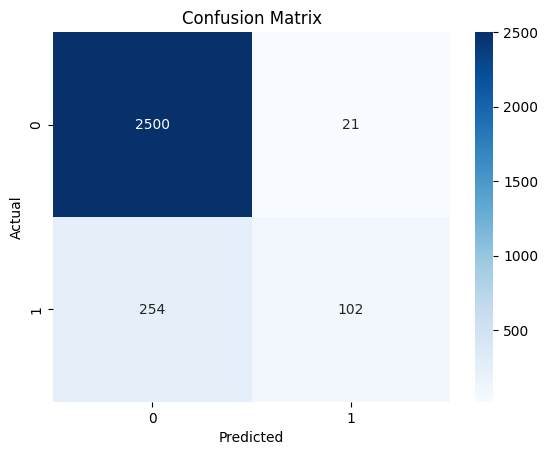

In [ ]:
# Visualizing the Confusion Matrix
import seaborn as sns

# Assuming 'conf_matrix' is already calculated (from your previous code)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Save the best model for future use
import joblib
joblib.dump(best_model, 'fraud_detection_model.pkl')

['fraud_detection_model.pkl']